<a href="https://colab.research.google.com/github/emptyfile560-coder/ML_LAB/blob/main/ML_Project_566.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:

# Email/SMS Spam Detection Using Machine Learning

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix



In [16]:
# 2. Load dataset
df = pd.read_csv('spam mail.csv')
print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (5572, 2)
  Category                                           Masseges
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...


In [17]:
# 3. Select and clean columns
df.columns = df.columns.str.strip()

# Match column names in your dataset
text_col = next(c for c in df.columns
                if c.strip().lower() in ['masseges', 'messages', 'message', 'text'])
label_col = next(c for c in df.columns
                 if c.strip().lower() in ['category', 'label', 'v1', 'class'])

df = df[[label_col, text_col]].dropna()
df.columns = ['Category', 'Message']

df['Category'] = df['Category'].astype(str).str.strip().str.lower()
df = df[df['Category'].isin(['spam', 'ham'])]

df['Label'] = df['Category'].map({'ham': 0, 'spam': 1})

print("\nMessage Counts:")
print(df['Category'].value_counts())


Message Counts:
Category
ham     4825
spam     747
Name: count, dtype: int64


In [18]:
# 4. Split data
X_train, X_test, y_train, y_test = train_test_split(
    df['Message'],
    df['Label'],
    test_size=0.2,
    random_state=42,
    stratify=df['Label']
)

In [19]:
# 5. Create and train model
model = Pipeline([
    ('tfidf', TfidfVectorizer(
        lowercase=True,
        stop_words='english',
        ngram_range=(1, 2)
    )),
    ('classifier', MultinomialNB())
])

model.fit(X_train, y_train)
print("\nModel trained successfully!")


Model trained successfully!


In [20]:
# 6. Evaluate model
y_pred = model.predict(X_test)

print("\nAccuracy: {:.2f}%".format(
    accuracy_score(y_test, y_pred) * 100
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['Ham', 'Spam'],
    zero_division=0
))


Accuracy: 96.23%

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       966
        Spam       1.00      0.72      0.84       149

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115



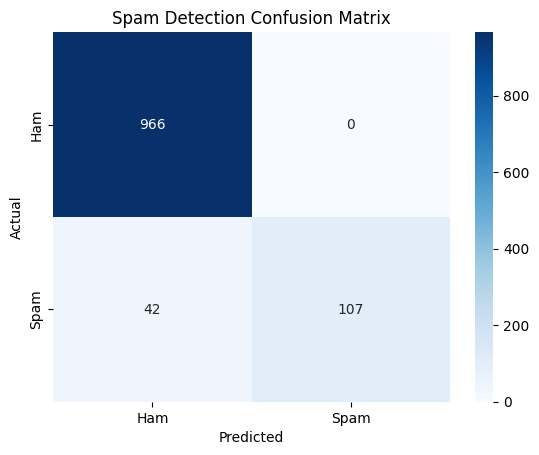

In [21]:
# 7. Confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Spam Detection Confusion Matrix')
plt.show()

In [22]:
# 8. Predict a new message
def detect_spam(message):
    prediction = model.predict([message])[0]
    print("\nMessage:", message)
    if prediction == 1:
        print("Result: SPAM")
    else:
        print("Result: HAM (Not Spam)")

detect_spam("Congratulations! You have won a free prize. Call now!")
detect_spam("Hello, are we meeting at college tomorrow?")


Message: Congratulations! You have won a free prize. Call now!
Result: SPAM

Message: Hello, are we meeting at college tomorrow?
Result: HAM (Not Spam)


In [23]:
# 9. Enter your own message
message = input("\nEnter a message to check: ")
detect_spam(message)


Enter a message to check: i call you later

Message: i call you later
Result: HAM (Not Spam)
